In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

import random
np.random.seed(42)

df = pd.read_csv("C:/Users/angel/Downloads/diabetes.csv")
print(df.head())


   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [ ]:
# x will be the 8 features
# y will be the outcome

X = df.drop(columns=['Outcome'])
y = df['Outcome']

# Split and scale data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# Accuracy on clean data
y_pred = model.predict(X_test_scaled)
base_accuracy = accuracy_score(y_test, y_pred)
print(f"Clean Accuracy: {base_accuracy:.4f}")



Clean Accuracy: 0.7532


In [ ]:
def add_gaussian_noise(X, sigma=0.1):
    noise = np.random.normal(0, sigma, X.shape)
    return X + noise

X_test_noisy = add_gaussian_noise(X_test_scaled, sigma=0.1)
y_pred_noisy = model.predict(X_test_noisy)
noisy_accuracy = accuracy_score(y_test, y_pred_noisy)
print(f"Gaussian Noise Accuracy (σ=0.1): {noisy_accuracy:.4f}")



Gaussian Noise Accuracy (σ=0.1): 0.7468


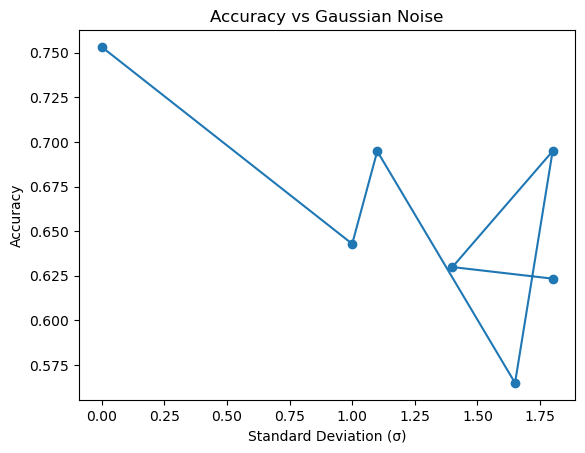

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

def add_gaussian_noise(X, sigma=0.1):
    noise = np.random.normal(0, sigma, X.shape)
    return X + noise

sigmas = [0,1,1.1,1.65,1.8,1.4,1.8]
accuracies = []

for sigma in sigmas:
    X_noisy = add_gaussian_noise(X_test_scaled, sigma=sigma)
    y_pred = model.predict(X_noisy)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

plt.plot(sigmas, accuracies, marker='o')
plt.xlabel("Standard Deviation (σ)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Gaussian Noise")
plt.show()


Adverserial robustness
A loss function is a mathematical tool that measures how far a model’s predictions deviate from the actual target values, guiding the optimization process by minimizing this error.
MSE and MAE
ability of the model to resist a special noisy input- adverserial input, adverserial debiasing.
adverserial input: adds to existing input, modifies the existing inputs, and fits the model to do a wrong predictons. tricks the model to make a wrong prediciton. This results in an increase in the loss function. adverserial robustness is the ability for the model to resist this adverserial pertubations
FGSM: fast gradient sgn method to generate the adverserial input
existing input plus add noise= adverserial input , if epsilon is large you want to make a larger noise addition
formula = SIGN of gradient of loss function(f(x),y) * epsilon + input

logistic regression model passes linear inputs through sigmoid
y predicted = sigmoid(z)
z = w1x1+w2x2+b
signmoid(z) = 1 / 1+e^-z


In [ ]:
import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = 2.0, -1.0, 0.5
x1, x2 =  1.0, 2.0
y_pred = logistic_regression_predict(x1, x2, w1, w2, b)
print("Predicted probability:", y_pred)


Linear combination (z): 0.5
Sigmoid(z): 0.6224593312018546
Predicted probability: 0.6224593312018546


the test sample belongs to class one here as the predicted prob is greater than 0.5- decision threshold
we want to now reverse this through FSGM
probability has to go below 0.5
gradient of loss function is apprximated = y pred- y
differentiate wit respect to x1 gives w1 and same for w2
y hat - y * weight vector

rate of change of loss with respect to x1
0.622 - 1 = -0.378 * w1
-0.378 * 2
-0.756

rate of change of loss with respect to x1
0.622 - 1 = -0.378 * w2
-0.378 * -1
0.378

x + epsilon*(
x + 0.1(-1,1)--> this are the signs of rate of change
(1,0  2,0) + (0.1(-1,  1)
0.9, 2.1

for epsilon 0.2
(1,0  2,0) + (0.2(-1,  1)
(0.8, 2.2)

In [ ]:
# doing the same thing to find the adverserial value
import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = 2.0, -1.0, 0.5
# x1, x2 =  1.0, 2.0
x1, x2 = 0.9, 2.1
y_pred = logistic_regression_predict(x1, x2, w1, w2, b)
print("Adverserial probability:", y_pred)


Linear combination (z): 0.19999999999999996
Sigmoid(z): 0.5498339973124778
Adverserial probability: 0.5498339973124778


Predicted probability: 0.6224593312018546
Adverserial probability: 0.5498339973124778
Adverserial probability 2: 0.47502081252106
 increased epsilon to 0.2 and got class 0 for Adverserial probability 2

In [ ]:

# doing the same thing to find the adverserial value
import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = 2.0, -1.0, 0.5
# x1, x2 =  1.0, 2.0
x1, x2 = 0.8, 2.2
y_pred = logistic_regression_predict(x1, x2, w1, w2, b)
print("Adverserial probability 2:", y_pred)


Linear combination (z): -0.10000000000000009
Sigmoid(z): 0.47502081252106
Adverserial probability 2: 0.47502081252106


In [ ]:
# problem 2

import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = 1.0, -2.0, -0.1
x1, x2 =  0.8, 0.1
y_pred2 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Predicted probability Q2:", y_pred2)
# class 1


Linear combination (z): 0.5000000000000001
Sigmoid(z): 0.6224593312018547
Predicted probability Q2: 0.6224593312018547


rate of change of loss with respect to x1
0.622 - 1 = -0.378 * w1
-0.378 * 1
-0.378

rate of change of loss with respect to x1
0.622 - 1 = -0.378 * w2
-0.378 * -2
.0756

x + epsilon*(
x + 0.2(-1,1)--> this are the signs of rate of change
(0.8,0  0.1,0) + (0.2(-1,  1)
0.6, 0.3


In [ ]:
# problem 2

import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = 1.0, -2.0, -0.1
x1, x2 =  0.6, 0.3
y_predq2 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Adverserial probability Q2:", y_predq2)
# class 0


Linear combination (z): -0.1
Sigmoid(z): 0.47502081252106
Adverserial probability Q2: 0.47502081252106


Predicted probability Q2: 0.6224593312018547 hence class 1
Adverserial probability Q2: 0.47502081252106 hence class 0 with epsilon as 0.2


In [ ]:
# problem 3

import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = 1.5, 1.0, -1.0
x1, x2 =  0.2, 0.4
y_pred3 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Predicted probability Q3:", y_pred3)
# class 0


Linear combination (z): -0.29999999999999993
Sigmoid(z): 0.4255574831883411
Predicted probability Q3: 0.4255574831883411


rate of change of loss with respect to x1
0.425 - 0 = -0.575 * w1
0.425 * 2

rate of change of loss with respect to x1
0.425 - 0 = 0.425 * w2


x + epsilon*(
x + 0.2(-1,1)--> this are the signs of rate of change
(0.2,0  0.4,0) + (0.2(1,  1)
0.4, 0.6


In [ ]:
# problem 3

import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = 1.5, 1.0, -1.0
x1, x2 =  0.4,0.6
y_pred3 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Predicted probability Q3:", y_pred3)
# class 1
# y=0

Linear combination (z): 0.20000000000000018
Sigmoid(z): 0.549833997312478
Predicted probability Q3: 0.549833997312478


In [ ]:
# problem 4

import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = 2, 1.0, -0.5
x1, x2 =  0.8, 0.7
y_pred4 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Predicted probability Q4:", y_pred3)
# class 1
# y = 1
y_true = 1

# Error term (difference between prediction and true label)
error = y_pred4 - y_true
print("Error (y_pred - y_true):", error)

# Rate of change of loss wrt inputs (gradient wrt x1, x2)
dx1 = error * w1
dx2 = error * w2
print("Rate of change wrt x1:", dx1)
print("Rate of change wrt x2:", dx2)

# Adversarial perturbation (FGSM-style)
epsilon = 0.2
x1_adv = x1 + epsilon * np.sign(dx1)
x2_adv = x2 + epsilon * np.sign(dx2)
print("adverserial x1: ", x1_adv)
print("adverserial x2: ", x2_adv)

Linear combination (z): 1.7999999999999998
Sigmoid(z): 0.8581489350995123
Predicted probability Q4: 0.549833997312478
Error (y_pred - y_true): -0.1418510649004877
Rate of change wrt x1: -0.2837021298009754
Rate of change wrt x2: -0.1418510649004877
adverserial x1:  0.6000000000000001
adverserial x2:  0.49999999999999994


In [ ]:
# problem 4

import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = 1.0, -2.0, -0.1
x1, x2 =  x1_adv, x2_adv
y_predq2 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Adverserial probability Q4:", y_predq2)
# class 0


Linear combination (z): -0.9000000000000001
Sigmoid(z): 0.289050497374996
Adverserial probability Q4: 0.289050497374996


rate of change of loss with respect to x1
0.858 - 1 = -0.142 * w1
-0.142 * 2
-0.284

rate of change of loss with respect to x1
0.858 - 1 = -0.378 * w2
-0.142 * 1


x + epsilon*(
x + 0.2(-1,1)--> this are the signs of rate of change
(0.8,0  0.7,0) + (0.2(-1,  -1)
0.6, 0.5

Predicted probability Q4: 0.8581489350995123 belongs to class 1
Adverserial probability Q2: 0.3775406687981455 belongs to class 0
with epsilon 0.2 and y = 1


In [ ]:
# problem 5 HW

import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = -2, 1.0, 0.2
x1, x2 =  0.5, 0.4
y_pred5 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Predicted probability Q5:", y_pred5)
# class 1
# y = 0
y_true = 0

# Error term (difference between prediction and true label)
error = y_pred4 - y_true
print("Error (y_pred - y_true):", error)

# Rate of change of loss wrt inputs (gradient wrt x1, x2)
dx1 = error * w1
dx2 = error * w2
print("Rate of change wrt x1:", dx1)
print("Rate of change wrt x2:", dx2)

# Adversarial perturbation (FGSM-style)
epsilon = 0.2
x1_adv = x1 + epsilon * np.sign(dx1)
x2_adv = x2 + epsilon * np.sign(dx2)
print("adverserial x1: ", x1_adv)
print("adverserial x2: ", x2_adv)



Linear combination (z): -0.39999999999999997
Sigmoid(z): 0.401312339887548
Predicted probability Q5: 0.401312339887548
Error (y_pred - y_true): 0.8021838885585818
Rate of change wrt x1: -1.6043677771171636
Rate of change wrt x2: 0.8021838885585818
adverserial x1:  0.3
adverserial x2:  0.6000000000000001


In [ ]:
# problem 5 HW

import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = -2, 1.0, 0.2
x1, x2 =  x1_adv, x2_adv
y_predq5 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Adverserial probability Q5:", y_predq5)
# class 1


Linear combination (z): 0.20000000000000012
Sigmoid(z): 0.549833997312478
Adverserial probability Q5: 0.549833997312478


In [ ]:
# problem 6 HW

import numpy as np

# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = -1.0, 2.0, 0
x1, x2 =  0.2, 0.8
y_pred6 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Predicted probability Q6:", y_pred6)
# class 0
# y = 0
y_true = 1

# Error term (difference between prediction and true label)
error = y_pred6 - y_true
print("Error (y_pred - y_true):", error)

# Rate of change of loss wrt inputs (gradient wrt x1, x2)
dx1 = error * w1
dx2 = error * w2
print("Rate of change wrt x1:", dx1)
print("Rate of change wrt x2:", dx2)

# Adversarial perturbation (FGSM-style)
epsilon = 0.2
x1_adv = x1 + epsilon * np.sign(dx1)
x2_adv = x2 + epsilon * np.sign(dx2)
print("adverserial x1: ", x1_adv)
print("adverserial x2: ", x2_adv)


Linear combination (z): 1.4000000000000001
Sigmoid(z): 0.8021838885585818
Predicted probability Q6: 0.8021838885585818
Error (y_pred - y_true): -0.1978161114414182
Rate of change wrt x1: 0.1978161114414182
Rate of change wrt x2: -0.3956322228828364
adverserial x1:  0.4
adverserial x2:  0.6000000000000001


In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression prediction
def logistic_regression_predict(x1, x2, w1, w2, b):
    z = (w1 * x1) + (w2 * x2) + b
    print("Linear combination (z):", z)

    # Apply sigmoid
    y_pred = sigmoid(z)
    print("Sigmoid(z):", y_pred)

    return y_pred

# Example usage
w1, w2, b = -1.0, 2.0, 0
x1, x2 =  x1_adv, x2_adv
y_predq6 = logistic_regression_predict(x1, x2, w1, w2, b)
print("Adverserial probability Q6:", y_predq6)
# class 1


Linear combination (z): 0.8000000000000002
Sigmoid(z): 0.6899744811276125
Adverserial probability Q6: 0.6899744811276125
